# 03 — Exploratory Data Analysis

**Stage 3 of the Tier A pipeline.** Hypothesis-driven: one section per branch of the Stage 0 issue tree
(`01` §0.4). Every chart carries an **Action Title** and a written **So What** and **Implication** beneath
it. Formal tests with effect sizes are `04`'s job; branch D (prediction) is `05`'s.

| Branch | Question | Exhibit |
|---|---|---|
| **A. The file** | What is one row, and are rows independent? | ex01 |
| **B. Power** | What sets Total: tier, type or generation? | ex02, ex03, ex04 |
| **C. Shape** | Once size is removed, does type set the stat profile? | ex05, ex06 |

Unless stated otherwise, the unit is the **721 species** (`is_species`); forms appear only where they are the subject.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "Pokemon.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"
STATS = ["hp", "atk", "def", "spa", "spd", "spe"]
STAT_LABEL = {"hp": "HP", "atk": "Attack", "def": "Defense", "spa": "Sp. Atk", "spd": "Sp. Def", "spe": "Speed"}
SHARES = [f"sh_{s}" for s in STATS]


def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text(encoding="utf-8")) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True, ensure_ascii=False), encoding="utf-8")
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C" --mode light --pairs all
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst pair dE 12.5 protan)
#     PASS normal-vision separation (21.1) | PASS contrast >= 3:1 on white
# Charts here never need more than three identity colours: Blue = the focus series, Teal = the
# second series, Amber = reference lines / thresholds. Everything else is Grey context.
# DESIGN.md's Teal #00857C FAILS the chroma floor (C = 0.097 < 0.10, reads as grey), so it is
# nudged to #008A7E on the same hue. Navy is text ink only — never a series fill.
# Diverging (type signature heatmap): Amber (below average) <- light grey -> Blue (above average).
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER, CYAN = "#051C2C", "#2251FF", "#008A7E", "#C1841C", "#00A9F4"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"
C_FOCUS, C_SECOND, C_REF, C_CONTEXT = BLUE, TEAL, AMBER, GREY


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
SOURCE = "Pokemon.csv (Kaggle 'Pokemon with stats', main-series games, Generations 1–6)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3. Placed under the lowest
    artist (axis labels, outside legends), so it never collides with them."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    y0 = min(ax.get_tightbbox(r).transformed(fig.transFigure.inverted()).y0 for ax in fig.axes)
    fig.text(0.005, y0 - 0.12 / fig.get_figheight(), f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")

from matplotlib.colors import LinearSegmentedColormap

DIVERGING = LinearSegmentedColormap.from_list("amber_blue", [AMBER, "#F4F6F8", BLUE])
df = pd.read_parquet(PROC / "pokemon_clean.parquet")
sp = df[df.is_species].copy()
print(f"{len(df)} rows, {len(sp)} species, {df.shape[1]} columns")
sp[STATS + ["total"]].describe().round(1).T.assign(skew=sp[STATS + ["total"]].skew().round(2))

800 rows, 721 species, 40 columns


,count,mean,std,min,25%,50%,75%,max,skew
hp,721.0,68.4,25.8,1.0,50.0,65.0,80.0,255.0,1.67
atk,721.0,75.1,29.1,5.0,54.0,75.0,95.0,165.0,0.31
def,721.0,70.7,29.2,5.0,50.0,65.0,85.0,230.0,1.12
spa,721.0,68.8,28.9,10.0,45.0,65.0,90.0,154.0,0.53
spd,721.0,69.2,26.9,20.0,50.0,65.0,85.0,230.0,1.02
spe,721.0,65.7,27.3,5.0,45.0,65.0,85.0,160.0,0.28
total,721.0,417.9,109.7,180.0,320.0,424.0,499.0,720.0,0.06


All six stats are right-skewed (HP most, Speed least), with medians of 65–75 and a long tail of specialists. That
is the review's expectation. The more useful question is what *drives* the spread, and the branches below take
that in turn.

## 3.1 Branch A — the file

**Hypothesis (Stage 0):** one row = one species; rows can be treated as independent. `01` showed both are false.
The exhibit puts the two facts side by side because together they decide how `05` must validate.

In [2]:
from sklearn.neighbors import NearestNeighbors

comp = df.form_kind.map({"base": "Species", "mega": "Mega Evolution", "alt": "Alternate form"}).value_counts()
X = sp[SHARES].to_numpy()
nb2 = NearestNeighbors(n_neighbors=2).fit(X).kneighbors(X, return_distance=False)
nn = np.where(nb2[:, 0] == np.arange(len(X)), nb2[:, 1], nb2[:, 0])
dex = sp.dex.to_numpy()
real = (np.abs(dex[nn] - dex) <= 2).mean()
rng = np.random.default_rng(RANDOM_STATE)
null = np.mean([(np.abs(p[nn] - p) <= 2).mean() for p in (rng.permutation(dex) for _ in range(2000))])
same_family = (sp.family.to_numpy()[nn] == sp.family.to_numpy()).mean()
print(comp.to_string())
print(f"\nnearest stat-shape neighbour within ±2 dex: {real:.1%}  (chance {null:.2%}, ratio {real/null:.0f}×)")
print(f"nearest stat-shape neighbour in the same family proxy: {same_family:.1%}")

form_kind
Species           721
Mega Evolution     48
Alternate form     31

nearest stat-shape neighbour within ±2 dex: 26.1%  (chance 0.56%, ratio 46×)
nearest stat-shape neighbour in the same family proxy: 24.7%


### Exhibit 1 — The 800 rows are 721 species plus 79 forms, and evolution siblings share a stat shape far more often than chance

  saved reports/figures/ex01_rows.png


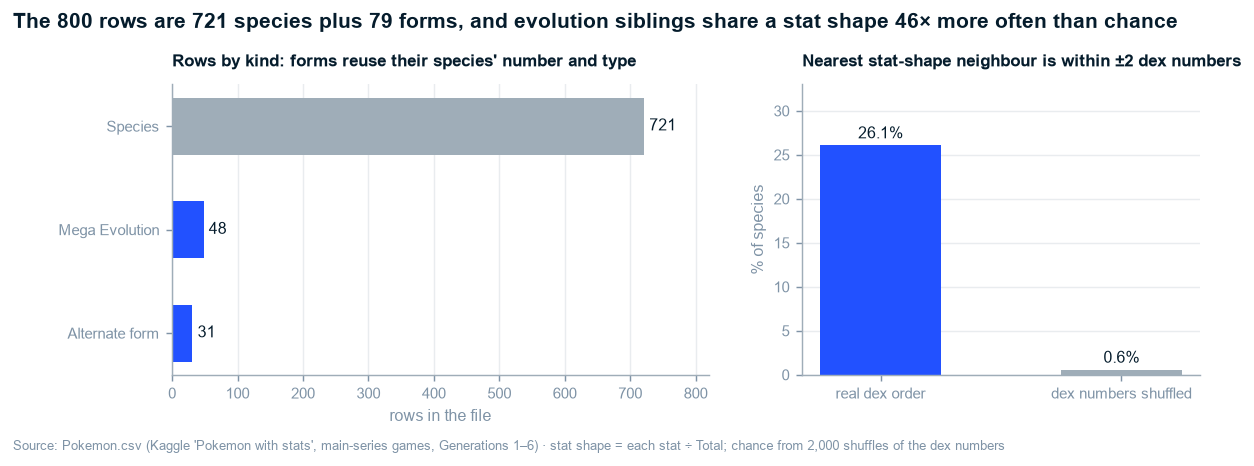

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.2, 2.9), gridspec_kw={"width_ratios": [1.35, 1]})
labels = ["Species", "Mega Evolution", "Alternate form"]
vals = [comp[l] for l in labels]
a1.barh(labels[::-1], vals[::-1], color=[GREY, BLUE, BLUE][::-1], height=0.55)
for y, v in enumerate(vals[::-1]):
    a1.text(v + 8, y, f"{v}", va="center", fontsize=9, color=NAVY)
a1.set_xlim(0, 820); a1.grid(axis="x"); a1.grid(axis="y", visible=False)
a1.set_xlabel("rows in the file")
a1.set_title("Rows by kind: forms reuse their species' number and type", fontsize=9.5)

a2.bar(["real dex order", "dex numbers shuffled"], [real * 100, null * 100], color=[BLUE, GREY], width=0.5)
for x, v in enumerate([real * 100, null * 100]):
    a2.text(x, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9, color=NAVY)
a2.set_ylabel("% of species")
a2.set_ylim(0, 33)
a2.set_title("Nearest stat-shape neighbour is within ±2 dex numbers", fontsize=9.5)
suptitle(fig, "The 800 rows are 721 species plus 79 forms, and evolution siblings share a stat shape "
              f"{real/null:.0f}× more often than chance", y=1.07)
finish(fig, "stat shape = each stat ÷ Total; chance from 2,000 shuffles of the dex numbers")
save(fig, "ex01_rows.png")
plt.show()

**So What:** two different kinds of duplication sit in this file. The 79 forms are near-copies of a species (same
number, same primary type). Evolution families are subtler: different species, but numbered consecutively and
built on the same proportions. A species' nearest match in stat shape is within two dex numbers 26% of the time,
against 0.6% by chance.

**Implication:** any model that learns type from stats and is checked with a random split will be partly
recognising families it has already seen. `05` validates with forms removed and families kept together, and
reports what a random split would have claimed.

## 3.2 Branch B — power (Total)

**Hypothesis (Stage 0):** Total is set by tier rules (legendary status, Mega Evolution), not by type or generation.

In [4]:
leg = sp.legendary_canon
print(sp.groupby(leg).total.describe().round(0))
print(f"\nlegendary/mythical species at Total >= 580: {(sp.total[leg] >= 580).sum()} of {leg.sum()}  "
      f"(below: {', '.join(sp.loc[leg & (sp.total < 580), 'name'])})")
print(f"non-legendary species at Total >= 580: {(sp.total[~leg] >= 580).sum()} — "
      + ", ".join(f"{n} {t}" for n, t in sp.loc[~leg & (sp.total >= 580), ['name', 'total']].values))
print(f"Total values used by legendary species: {sorted(sp.total[leg].unique())}")

                 count   mean   std    min    25%    50%    75%    max
legendary_canon                                                       
False            667.0  402.0  97.0  180.0  315.0  410.0  490.0  670.0
True              54.0  615.0  46.0  480.0  580.0  600.0  670.0  720.0

legendary/mythical species at Total >= 580: 53 of 54  (below: Phione)
non-legendary species at Total >= 580: 8 — Dragonite 600, Tyranitar 600, Slaking 670, Salamence 600, Metagross 600, Garchomp 600, Hydreigon 600, Goodra 600
Total values used by legendary species: [np.int64(480), np.int64(580), np.int64(600), np.int64(660), np.int64(670), np.int64(680), np.int64(720)]


### Exhibit 2 — Power comes in tiers: legendary species start at 580, and seven non-legendaries sit at exactly 600

  saved reports/figures/ex02_power_tiers.png


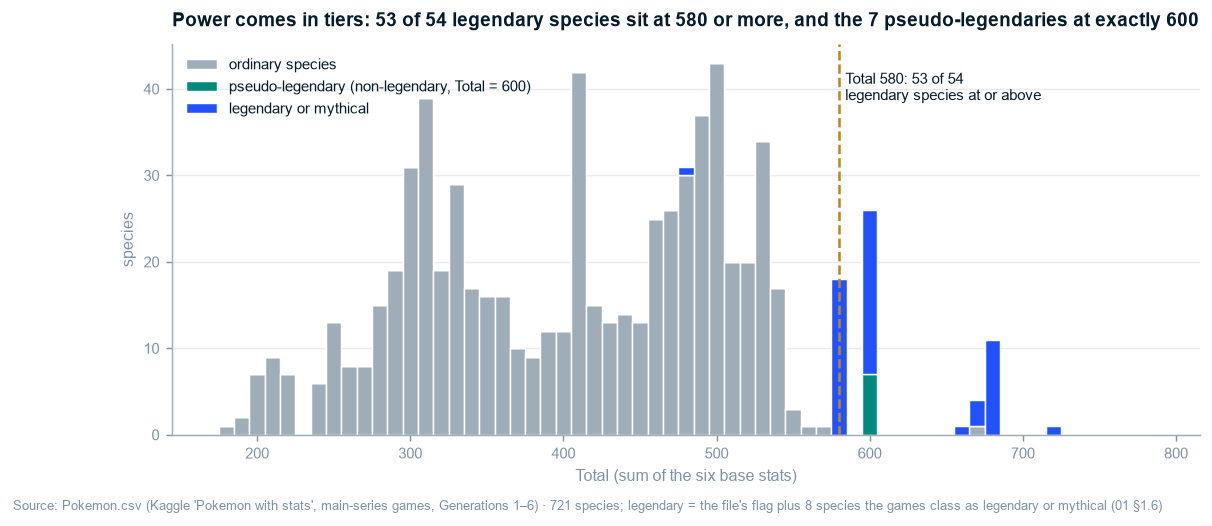

In [5]:
bins = np.arange(175, 790, 10)
groups = [("ordinary species", ~leg & ~sp.pseudo_600, GREY),
          ("pseudo-legendary (non-legendary, Total = 600)", sp.pseudo_600, TEAL),
          ("legendary or mythical", leg, BLUE)]
fig, ax = plt.subplots(figsize=(10.2, 3.9))
ax.hist([sp.total[m] for _, m, _ in groups], bins=bins, stacked=True, color=[c for *_, c in groups],
        label=[l for l, *_ in groups], edgecolor="white", lw=0.8)
ax.axvline(580, color=AMBER, ls="--", lw=1.4)
n_hi = int((sp.total[leg] >= 580).sum())
ax.text(584, ax.get_ylim()[1] * 0.93, f"Total 580: {n_hi} of {int(leg.sum())}\nlegendary species at or above",
        fontsize=8.2, color=NAVY, va="top")
ax.set_xlabel("Total (sum of the six base stats)"); ax.set_ylabel("species")
ax.legend(loc="upper left")
ax.set_title(f"Power comes in tiers: {n_hi} of {int(leg.sum())} legendary species sit at 580 or more, "
             f"and the {int(sp.pseudo_600.sum())} pseudo-legendaries at exactly 600")
finish(fig, "721 species; legendary = the file's flag plus 8 species the games class as legendary or mythical (01 §1.6)")
save(fig, "ex02_power_tiers.png")
plt.show()

**So What:** Total is not a smooth continuum at the top. Legendary and mythical species occupy a few fixed values
(580, 600, 660, 670, 680, 720). One non-legendary per generation, roughly, gets the "pseudo-legendary" 600 at the end
of a slow three-stage line. Below 580, the ordinary roster spreads from 180 to 540 with a bulge around 450–500,
where most final evolutions sit.

**Implication:** a designer can read a **power ladder** straight off this file: ordinary creatures below 580,
one 600-point pseudo-legendary line per roster, legendaries at fixed steps from 580. Phione (480) is the one
legendary-class exception, and Slaking (670) the one ordinary creature above the line. `04` tests the tiers formally.

In [6]:
megas = df[df.form_kind == "mega"].merge(sp[["dex", "total"]], on="dex", suffixes=("", "_species"))
megas["uplift"] = megas.total - megas.total_species
alts = df[df.form_kind == "alt"].merge(sp[["dex", "total"]], on="dex", suffixes=("", "_species"))
alts["uplift"] = alts.total - alts.total_species
print("Mega uplift:", megas.uplift.value_counts().to_dict())
print("Alternate-form uplift:", alts.uplift.value_counts().sort_index().to_dict())
print("\nMegas by species Total band:", megas.total_species.describe()[["min", "50%", "max"]].to_dict())

Mega uplift: {100: 47, 90: 1}
Alternate-form uplift: {0: 20, 40: 2, 60: 1, 80: 6, 100: 2}

Megas by species Total band: {'min': 380.0, '50%': 510.0, 'max': 680.0}


### Exhibit 3 — Mega Evolution is a fixed budget: 47 of 48 Megas add exactly 100 points to their species

  saved reports/figures/ex03_mega.png


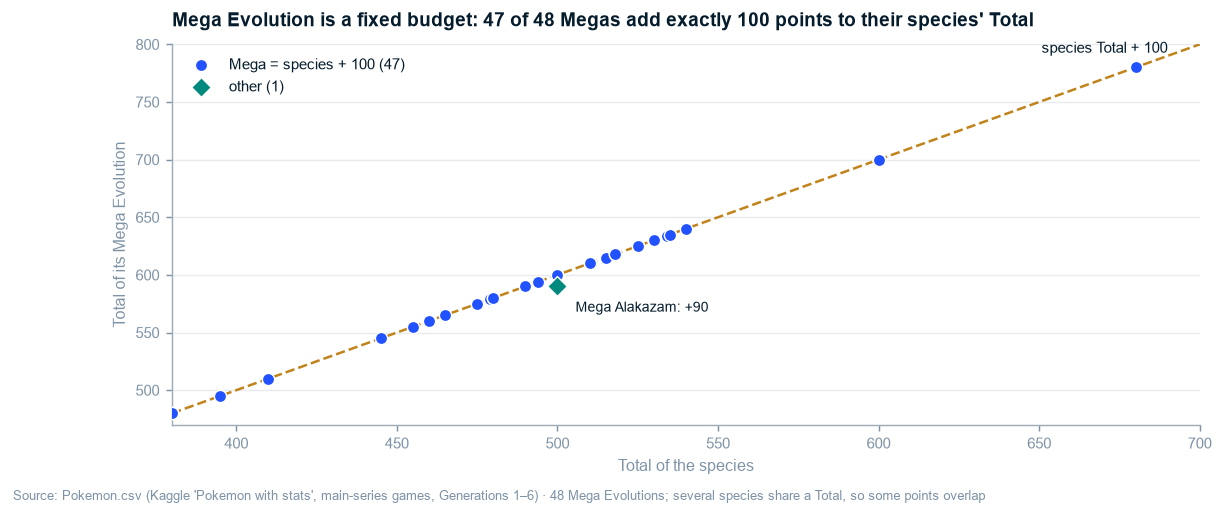

In [7]:
fig, ax = plt.subplots(figsize=(10.2, 3.8))
xs = np.array([380, 700])
ax.plot(xs, xs + 100, color=AMBER, ls="--", lw=1.4, zorder=1)
ax.text(690, 790, "species Total + 100", color=NAVY, fontsize=8.2, ha="right", va="bottom")
on = megas.uplift == 100
ax.scatter(megas.total_species[on], megas.total[on], s=46, color=BLUE, edgecolor="white", lw=0.8, zorder=3,
           label=f"Mega = species + 100 ({int(on.sum())})")
ax.scatter(megas.total_species[~on], megas.total[~on], s=60, marker="D", color=TEAL, edgecolor="white", lw=0.8,
           zorder=3, label=f"other ({int((~on).sum())})")
for _, r in megas[~on].iterrows():
    ax.annotate(f"{r['name']}: +{r.uplift}", (r.total_species, r.total), xytext=(10, -14),
                textcoords="offset points", fontsize=8, color=NAVY)
ax.set_xlim(380, 700); ax.set_ylim(470, 800)
ax.set_xlabel("Total of the species"); ax.set_ylabel("Total of its Mega Evolution")
ax.legend(loc="upper left")
ax.set_title(f"Mega Evolution is a fixed budget: {int(on.sum())} of {len(megas)} Megas add exactly 100 "
             "points to their species' Total")
finish(fig, "48 Mega Evolutions; several species share a Total, so some points overlap")
save(fig, "ex03_mega.png")
plt.show()

**So What:** the clearest design rule in the file. A Mega gets +100 points (the one exception, Mega Alakazam,
gets +90), redistributed across stats, and keeps its species' primary type. Alternate forms follow no single rule:
most are a 0-point re-spread of the same Total (Rotom, Deoxys, the Therian formes), a few add points.

**Implication:** for a new roster, a temporary power-up form can be specified as "+100 Total, same primary type",
and balance work then goes into *where* the 100 points go, not how many there are.

**Hypothesis (Stage 0):** no power creep across generations.

In [8]:
ordinary = sp[~sp.legendary_canon]
gen = ordinary.groupby("generation").total.agg(["size", "median", "mean"]).round(0)
gen["q25"] = ordinary.groupby("generation").total.quantile(0.25)
gen["q75"] = ordinary.groupby("generation").total.quantile(0.75)
gen["legendary_share"] = sp.groupby("generation").legendary_canon.mean().round(3)
gen

,size,median,mean,q25,q75,legendary_share
generation,,,,,,
1,146,405.0,400.0,320.00,490.00,0.033
2,94,408.0,393.0,315.00,468.75,0.060
3,125,400.0,385.0,300.00,465.00,0.074
4,93,450.0,420.0,330.00,510.00,0.131
5,143,418.0,409.0,316.00,488.00,0.083
6,66,417.0,412.0,326.25,499.75,0.083


### Exhibit 4 — No steady power creep: the median ordinary species sits between 400 and 450 in every generation

  saved reports/figures/ex04_generation.png


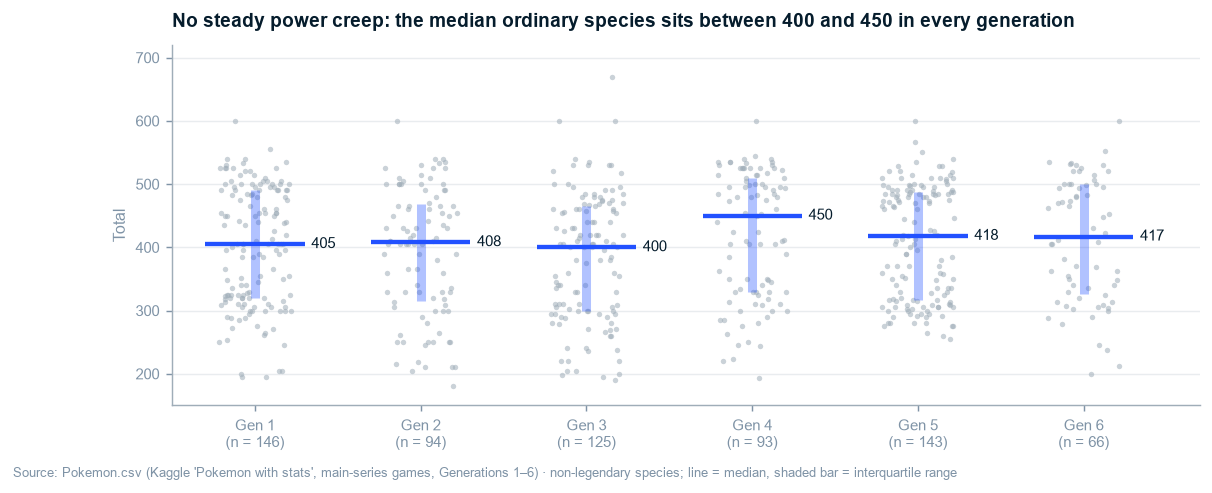

In [9]:
fig, ax = plt.subplots(figsize=(10.2, 3.6))
for g, sub in ordinary.groupby("generation"):
    jit = rng.uniform(-0.22, 0.22, len(sub))
    ax.scatter(g + jit, sub.total, s=9, color=GREY, alpha=0.55, lw=0, zorder=1)
    ax.vlines(g, gen.loc[g, "q25"], gen.loc[g, "q75"], color=BLUE, lw=5, zorder=2, alpha=0.35)
    ax.hlines(gen.loc[g, "median"], g - 0.3, g + 0.3, color=BLUE, lw=2.4, zorder=3)
    ax.text(g + 0.34, gen.loc[g, "median"], f"{gen.loc[g, 'median']:.0f}", va="center", fontsize=8.5, color=NAVY)
ax.set_xticks(range(1, 7), [f"Gen {g}\n(n = {int(gen.loc[g, 'size'])})" for g in range(1, 7)])
ax.set_ylabel("Total"); ax.set_ylim(150, 720); ax.set_xlim(0.5, 6.7)
lo, hi = gen["median"].min(), gen["median"].max()
ax.set_title(f"No steady power creep: the median ordinary species sits between {lo:.0f} and {hi:.0f} in every generation")
finish(fig, "non-legendary species; line = median, shaded bar = interquartile range")
save(fig, "ex04_generation.png")
plt.show()

**So What:** Generation 4 stands out (median 450, against 400–418 elsewhere), and Generations 5 and 6 fall back.
That is a bump, not a trend. Gen 4 added many late evolutions to older lines (Magnezone, Rhyperior, Togekiss…),
so it holds an unusually high share of final-stage creatures. That is a roster-mix effect, not a raised budget.
`04` tests the trend and checks it at family level.

**Implication:** the budget ladder from ex02 does not need a per-generation adjustment. A new roster can reuse the
Gen 1–6 bands directly.

## 3.3 Branch C — shape (stat shares)

**Hypothesis (from the review):** "stats are positively correlated, so multicollinearity matters."

In [10]:
raw_corr = sp[STATS].corr(method="spearman").rename(index=STAT_LABEL, columns=STAT_LABEL)
sh_corr = sp[SHARES].corr(method="spearman")
sh_corr.index = sh_corr.columns = [STAT_LABEL[s] for s in STATS]
off = ~np.eye(6, dtype=bool)
print(f"raw stats: {(raw_corr.where(off) > 0).sum().sum() // 2} of 15 pairs positive; mean ρ {raw_corr.where(off).stack().mean():.2f}")
print(f"shares   : {(sh_corr.where(off) < 0).sum().sum() // 2} of 15 pairs negative; most negative:")
pairs = sh_corr.where(np.triu(off)).stack().sort_values()
print(pairs.head(4).round(2).to_string())

raw stats: 15 of 15 pairs positive; mean ρ 0.39
shares   : 10 of 15 pairs negative; most negative:
Attack   Sp. Def   -0.56
Defense  Speed     -0.51
         Sp. Atk   -0.41
Attack   Sp. Atk   -0.36


### Exhibit 5 — Raw stats all rise together; once size is removed, the trade-offs appear

  saved reports/figures/ex05_correlation.png


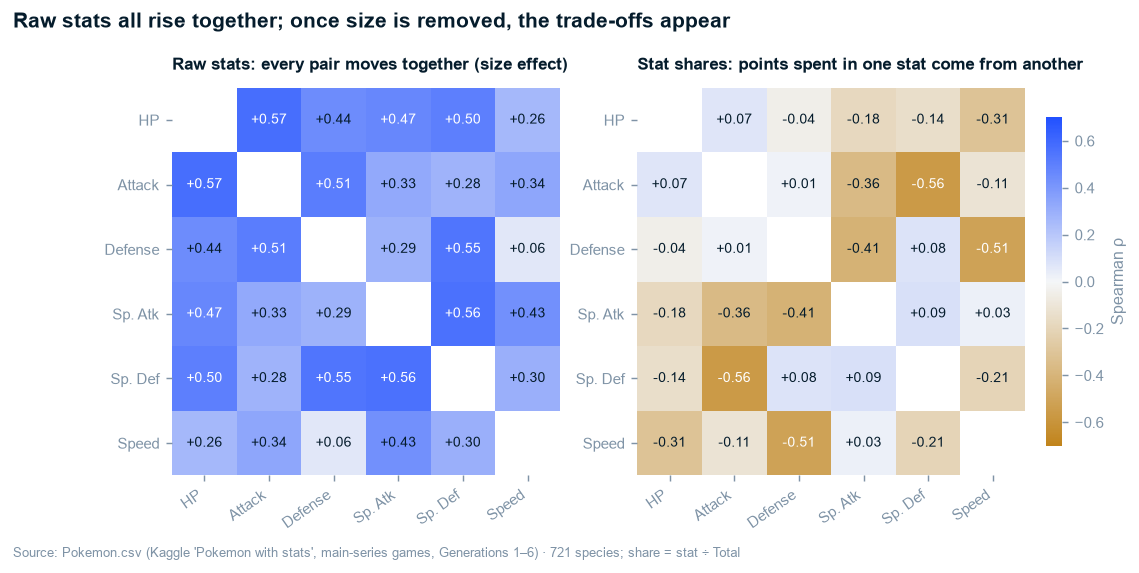

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1))
for ax, (m, ttl) in zip(axes, [(raw_corr, "Raw stats: every pair moves together (size effect)"),
                               (sh_corr, "Stat shares: points spent in one stat come from another")]):
    im = ax.imshow(m.where(off), cmap=DIVERGING, vmin=-0.7, vmax=0.7)
    ax.set_xticks(range(6), m.columns, rotation=35, ha="right"); ax.set_yticks(range(6), m.index)
    ax.grid(False)
    for i in range(6):
        for j in range(6):
            if i != j:
                v = m.iloc[i, j]
                ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.6,
                        color="white" if abs(v) > 0.45 else NAVY)
    ax.set_title(ttl, fontsize=9.3)
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("Spearman ρ", color=SLATE); cb.outline.set_visible(False)
suptitle(fig, "Raw stats all rise together; once size is removed, the trade-offs appear", y=1.0)
finish(fig, "721 species; share = stat ÷ Total")
save(fig, "ex05_correlation.png")
plt.show()

**So What:** the review's "stats are positively correlated" is true of raw stats, but it is a size effect:
evolved and legendary creatures are bigger everywhere. Divide by Total and the design trade-offs appear. Attack
against Sp. Def (ρ ≈ −0.55), Defense against Speed (≈ −0.5), Defense against Sp. Atk (≈ −0.4). Designers spend a
fixed budget, and these are the stats they trade.

**Implication:** comparing types on raw stats mostly compares their evolution and legendary mix. Type
signatures (next) and the classifier (`05`) use **shares**, which hold power constant.

**Hypothesis (Stage 0, from the review):** Steel, Rock, Ghost and Dragon have clear stat signatures.

In [12]:
overall = sp[SHARES].mean()
prof = sp.groupby("type1", observed=True)[SHARES].mean()
dev = (prof - overall) * 100                       # percentage points of Total, vs the average species
dev.columns = [STAT_LABEL[s] for s in STATS]
n_type = sp.type1.value_counts()
dev["strength"] = dev.abs().max(axis=1)
dev["small"] = n_type.reindex(dev.index) < 10              # too few species to judge: shown last
dev = dev.sort_values(["small", "strength"], ascending=[True, False])
print((prof * 100).round(1).rename(columns=lambda c: STAT_LABEL[c[3:]]).assign(n=n_type).loc[dev.index].to_string())
print("\naverage species' shares (%):", (overall * 100).round(1).rename(lambda c: STAT_LABEL[c[3:]]).to_dict())

            HP  Attack  Defense  Sp. Atk  Sp. Def  Speed    n
type1                                                        
Steel     14.0    19.0     25.2     14.2     16.3   11.3   22
Rock      14.8    20.4     23.1     13.5     16.4   11.8   41
Fighting  17.6    23.3     15.9     12.0     15.6   15.6   25
Psychic   16.2    13.3     14.6     20.8     18.7   16.3   47
Fairy     18.1    14.7     16.2     18.8     20.8   11.3   17
Electric  14.1    16.1     13.9     19.6     16.0   20.2   36
Ground    17.1    21.8     19.3     12.1     14.6   15.1   30
Normal    19.7    18.1     14.7     13.8     15.7   18.0   93
Ghost     14.4    15.7     18.1     19.2     18.2   14.4   23
Dragon    15.5    20.8     15.9     15.9     16.5   15.4   24
Fire      15.5    18.5     14.6     18.8     15.7   16.9   47
Dark      15.4    20.1     15.7     16.0     15.4   17.4   28
Bug       15.8    17.7     19.0     14.5     16.7   16.3   63
Grass     16.2    17.2     17.0     18.1     17.0   14.6   66
Ice     

### Exhibit 6 — Some types have a clear stat signature; about half are shaped like the average species

  saved reports/figures/ex06_signatures.png


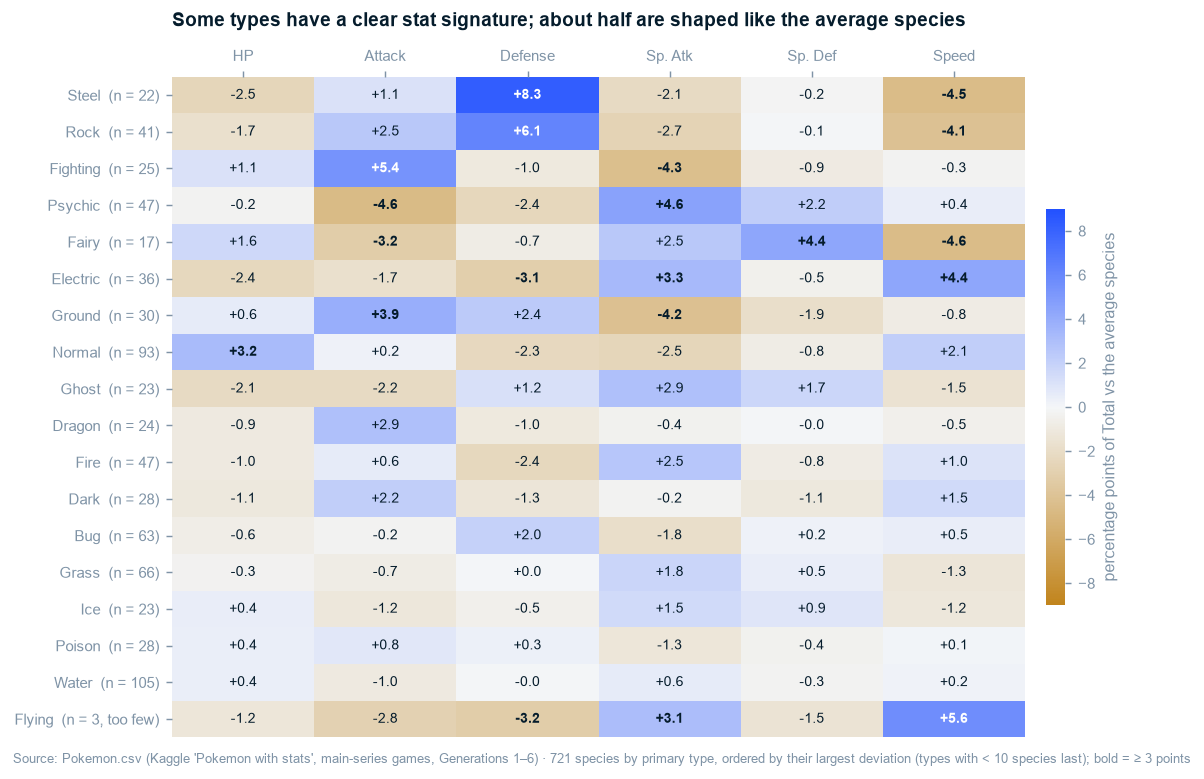

In [13]:
D = dev.drop(columns=["strength", "small"])
fig, ax = plt.subplots(figsize=(10.2, 6.6))
lim = np.ceil(D.abs().max().max())
im = ax.imshow(D.to_numpy(), cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(6), D.columns); ax.xaxis.tick_top()
ax.set_yticks(range(len(D)), [f"{t}  (n = {n_type[t]}{', too few' if n_type[t] < 10 else ''})" for t in D.index])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(D.shape[0]):
    for j in range(6):
        v = D.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > lim * 0.55 else NAVY, fontweight="bold" if abs(v) >= 3 else "normal")
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cb.set_label("percentage points of Total vs the average species", color=SLATE); cb.outline.set_visible(False)
ax.set_title("Some types have a clear stat signature; about half are shaped like the average species", pad=28)
finish(fig, "721 species by primary type, ordered by their largest deviation (types with < 10 species last); bold = ≥ 3 points")
save(fig, "ex06_signatures.png")
plt.show()

**So What:** the familiar archetypes are real for the types at the top. Steel and Rock put roughly 6–8 extra points
of every hundred into Defense and take them from Speed and Sp. Atk. Fighting is an Attack type, Psychic and Fairy are
special types, Electric is fast (so is Flying, but with 3 species), and Normal leans on HP. Further down, Water, Poison, Grass, Ice and Bug
deviate by about two points or less in every stat: their stat line looks like the average species.
Ghost and Dragon, two of the review's four expected signatures, sit in the middle of the table, not the top.

**Implication:** type templates make sense for the top of this table only. `04` decides which signatures hold up
under a test that respects evolution families, because a type with three big families can look distinctive just from
repeating one design.

In [14]:
kf_update(
    stat_skew={STAT_LABEL[s]: float(sp[s].skew()) for s in STATS},
    nn_family_rate=float(same_family), nn_ratio=float(real / null),
    raw_corr_mean=float(raw_corr.where(off).stack().mean()),
    share_corr_pairs={f"{a} × {b}": float(v) for (a, b), v in pairs.head(4).items()},
    gen_median={int(g): float(v) for g, v in gen["median"].items()},
    gen_n={int(g): int(v) for g, v in gen["size"].items()},
    leg_at_580=int((sp.total[leg] >= 580).sum()), leg_below_580=list(sp.loc[leg & (sp.total < 580), "name"]),
    leg_total_values=sorted(int(v) for v in sp.total[leg].unique()),
    ordinary_max_total=int(sp.total[~leg].max()), ordinary_median_total=float(sp.total[~leg].median()),
    ordinary_ceiling=int(sp.loc[~leg & ~sp.pseudo_600 & (sp.name != "Slaking"), "total"].max()),
    ordinary_ceiling_name=str(sp.loc[~leg & ~sp.pseudo_600 & (sp.name != "Slaking")].nlargest(1, "total")["name"].iloc[0]),
    alt_uplift_zero=int((alts.uplift == 0).sum()), n_alt_forms=int(len(alts)),
    sig_dev_pp={t: {c: float(D.loc[t, c]) for c in D.columns} for t in D.index},
    sig_strength={t: float(dev.loc[t, "strength"]) for t in dev.index},
    n_type1_species={t: int(v) for t, v in n_type.items()},
    avg_share_pct={STAT_LABEL[s[3:]]: float(v * 100) for s, v in overall.items()},
)

  _key_figures.json <- stat_skew, nn_family_rate, nn_ratio, raw_corr_mean, share_corr_pairs, gen_median, gen_n, leg_at_580, leg_below_580, leg_total_values, ordinary_max_total, ordinary_median_total, ordinary_ceiling, ordinary_ceiling_name, alt_uplift_zero, n_alt_forms, sig_dev_pp, sig_strength, n_type1_species, avg_share_pct  (53 figures total)


## Ghost deck — updated after EDA

| Stage 0 expectation | After EDA |
|---|---|
| Part I: "800 rows are [x] species plus [y] forms; rows are [not] independent" | **721 + 79; not independent:** forms copy species, families share shape 47× more than chance (ex01) |
| Part II: "Total is set by tier rules, not type or generation" | **Supported:** legendary floor 580, pseudo 600, Mega +100 (ex02, ex03); no creep, a Gen 4 bump (ex04) |
| Part III: "[n] of 18 types carry a signature" | **About half**, but the review's Ghost and Dragon are not among the clearest (ex06); must be tested at family level in `04` |
| New: the review's "positive correlation" | **A size effect;** shares show the real trade-offs (ex05). Shares become the modelling features |
| Part IV: "[go / no-go] on a design check" | To `05`, with forms removed and families grouped |

## Stage 3 — Gate Checklist

- [x] Profile reviewed (`01` §1.3–1.4 plus the describe table above); no automated profiler needed for 13 columns
- [x] Each Stage 0 hypothesis EDA can address has an analysis (A, B1–B3, C1–C2); C3 and D go to `05`
- [x] Distributions and relationships visualised and annotated · [x] All titles are action titles
- [x] Every finding has a So What and an Implication
- [x] Ghost deck updated (table above)
- [x] Data issues looped back to `02` (`pseudo_600`, pass 2) · [x] Findings documented